# 2. Train and evaluate a first model

In this lesson, we will split the Iris data into training and test sets, compare a simple decision tree with a basic baseline, and evaluate predictions on data the models did not train on.

## Learning goals
- Explain why we keep test data separate from training data.
- Split the data while keeping species proportions similar in both sets.
- Fit a classifier and compare it with a simple baseline.
- Read accuracy, a classification report, and a confusion matrix.

Run the cells from top to bottom. Do not use the test set to choose model settings; it is reserved for an honest final evaluation.

## 1. Load features and target

`X` contains the four flower measurements (features). `y` contains the species (target). We use the same built-in dataset as the exploration notebook.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print(f"Features: {list(X.columns)}")
print(f"Target classes: {list(iris.target_names)}")
print(f"Examples: {len(X)}")

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Examples: 150


## 2. Split into training and test data

The model learns from the training set. The test set simulates new examples and is used only to check how well the trained model generalizes. `stratify=y` keeps the class proportions similar in both sets; `random_state=42` makes this split reproducible.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training examples: {len(X_train)}")
print(f"Test examples: {len(X_test)}")
print("Training class counts:")
print(y_train.map(dict(enumerate(iris.target_names))).value_counts().sort_index())
print("Test class counts:")
print(y_test.map(dict(enumerate(iris.target_names))).value_counts().sort_index())

Training examples: 120
Test examples: 30
Training class counts:
target
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64
Test class counts:
target
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64


## 3. Establish a simple baseline

A model should do better than a simple reference. This baseline always predicts the most common species in the training data. Because the Iris classes are balanced, it should get about one-third of the test examples correct.

In [3]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Baseline accuracy: {baseline_accuracy:.1%}")

Baseline accuracy: 33.3%


## 4. Train a decision tree

A decision tree learns a sequence of measurement-based questions that separate the species. We set a maximum depth to keep this first model small and easy to reason about. The model is fitted only on training examples.

In [4]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

test_predictions = model.predict(X_test)
model_accuracy = accuracy_score(y_test, test_predictions)
print(f"Decision tree accuracy: {model_accuracy:.1%}")
print(f"Baseline accuracy:      {baseline_accuracy:.1%}")

Decision tree accuracy: 96.7%
Baseline accuracy:      33.3%


## 5. Inspect the evaluation

Accuracy is the share of predictions that are correct. The classification report also gives **precision** (how often predictions for a species are right), **recall** (how many examples of a species were found), and their combined **F1-score**. These metrics help show performance by species rather than hiding it in one overall number.

In [5]:
print(classification_report(y_test, test_predictions, target_names=iris.target_names, zero_division=0))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



The confusion matrix compares the true species (rows) with the predicted species (columns). Correct predictions appear along the diagonal; off-diagonal counts are mistakes.

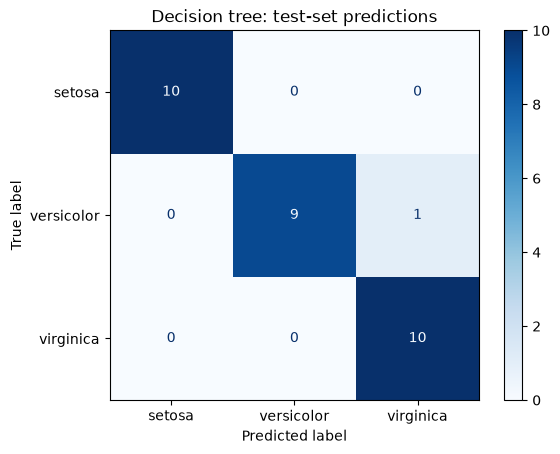

In [7]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=iris.target_names,
    cmap="Blues",
)
plt.title("Decision tree: test-set predictions")
plt.show()

## Your notes

1. How many examples were used for training and how many for testing?
2. How much better (if at all) was the decision tree than the baseline?
3. Which species, if any, did the model confuse? What does that mean for the flowers it was tested on?
4. Why is it important that the test examples were not used to fit the model?

## What comes next

Next, we will look more closely at model evaluation and common pitfalls, then improve the model carefully without repeatedly tuning against the test set.